In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
root=Path("..")/"Experiment_Results"/"HasilEksperimenTahap2"/"Tahap2A"
sources = {
    "Mutation": root / "Mutation",
    "Crossover_95": root / "Crossover",
}
dataframes=[]
for source_name, folder in sources.items():
    if source_name == "Crossover_95":
        matching_folders = [
            path for path in folder.rglob("*")
            if path.is_dir() and path.name.endswith("95")
        ]

        csv_files = sorted({
            csv_file
            for matching_folder in matching_folders
            for csv_file in matching_folder.rglob("*.csv")
        })
    else:
        csv_files = sorted(folder.rglob("*.csv"))
    for csv_file in csv_files:
        df = pd.read_csv(csv_file)

        # Menyimpan asal data agar baris gabungan bisa dilacak
        df["source_group"] = source_name
        df["source_file"] = str(csv_file.relative_to(root))

        dataframes.append(df)
if dataframes:
    df_all=pd.concat(dataframes, ignore_index=True)
else:
    df_all=pd.DataFrame()
    print("Tidak ada file CSV yang berhasil dibaca.")

In [4]:
df_M04_Mutation=df_all[df_all["model_id"]=="M04"].copy()
df_M04_Mutation_summary=(df_M04_Mutation.groupby(["grid_rows", "pm", "map_type"], as_index=False).agg(
    mean_cost=("best_cost", "mean"),
    best_run=("best_cost", "min"),
    worst_run=("best_cost", "max"),
    std_cost=("best_cost", "std"),
    total_runs=("best_cost", "count")
))
display(df_M04_Mutation_summary)

,grid_rows,pm,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,0.01,Cluster,2.503333,2.500000,2.600000,0.018257,30
1,10,0.01,Maze,3.333333,3.333333,3.333333,0.000000,30
2,10,0.01,Random,2.596429,2.416667,2.928571,0.157275,60
3,10,0.03,Cluster,2.500000,2.500000,2.500000,0.000000,30
4,10,0.03,Maze,3.333333,3.333333,3.333333,0.000000,30
5,10,0.03,Random,2.593452,2.416667,2.785714,0.158251,60
6,10,0.05,Cluster,2.500000,2.500000,2.500000,0.000000,30
7,10,0.05,Maze,3.333333,3.333333,3.333333,0.000000,30
8,10,0.05,Random,2.596230,2.416667,2.857143,0.156901,60
9,20,0.01,Cluster,4.788288,4.783784,4.810811,0.010245,30


In [5]:
table_random = (
    df_M04_Mutation_summary[df_M04_Mutation_summary["map_type"] == "Random"]
    .sort_values("pm")
)

display(table_random)
table_maze = (
    df_M04_Mutation_summary[df_M04_Mutation_summary["map_type"] == "Maze"]
    .sort_values("pm")
)

display(table_maze)
table_cluster = (
    df_M04_Mutation_summary[df_M04_Mutation_summary["map_type"] == "Cluster"]
    .sort_values("pm")
)

display(table_cluster)

,grid_rows,pm,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
2,10,0.01,Random,2.596429,2.416667,2.928571,0.157275,60
11,20,0.01,Random,6.247874,6.025000,6.487179,0.217588,60
20,40,0.01,Random,6.699810,6.551282,6.906250,0.114759,60
5,10,0.03,Random,2.593452,2.416667,2.785714,0.158251,60
23,40,0.03,Random,6.684997,6.519231,6.862500,0.102919,60
14,20,0.03,Random,6.247906,6.025000,6.512821,0.220209,60
8,10,0.05,Random,2.596230,2.416667,2.857143,0.156901,60
17,20,0.05,Random,6.244551,6.025000,6.487179,0.221472,60
26,40,0.05,Random,6.663763,6.519231,6.912500,0.104008,60


,grid_rows,pm,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
1,10,0.01,Maze,3.333333,3.333333,3.333333,0.000000,30
10,20,0.01,Maze,6.809402,6.794872,6.846154,0.017408,30
19,40,0.01,Maze,6.930115,6.848276,7.117241,0.064511,30
4,10,0.03,Maze,3.333333,3.333333,3.333333,0.000000,30
22,40,0.03,Maze,6.900230,6.848276,6.993103,0.040970,30
13,20,0.03,Maze,6.812821,6.794872,6.846154,0.013718,30
7,10,0.05,Maze,3.333333,3.333333,3.333333,0.000000,30
16,20,0.05,Maze,6.808547,6.794872,6.846154,0.014650,30
25,40,0.05,Maze,6.888736,6.841379,7.124138,0.054386,30


,grid_rows,pm,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,0.01,Cluster,2.503333,2.500000,2.600000,0.018257,30
9,20,0.01,Cluster,4.788288,4.783784,4.810811,0.010245,30
18,40,0.01,Cluster,5.510968,5.458065,5.612903,0.041550,30
3,10,0.03,Cluster,2.500000,2.500000,2.500000,0.000000,30
21,40,0.03,Cluster,5.487097,5.445161,5.554839,0.024421,30
12,20,0.03,Cluster,4.791892,4.783784,4.837838,0.016107,30
6,10,0.05,Cluster,2.500000,2.500000,2.500000,0.000000,30
15,20,0.05,Cluster,4.786486,4.783784,4.810811,0.008247,30
24,40,0.05,Cluster,5.477849,5.445161,5.587097,0.026946,30


In [6]:
df_M04_Mutation_summary["rank_mean_cost"] = (
    df_M04_Mutation_summary
    .groupby(["grid_rows", "map_type"])["mean_cost"]
    .rank(method="average", ascending=True)
)
avg_rank_M04 = (
    df_M04_Mutation_summary
    .groupby("pm", as_index=False)
    .agg(
        avg_rank_mean=("rank_mean_cost", "mean"),
        avg_mean_cost=("mean_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_mean_cost", "count")
    )
    .sort_values(["avg_mean_cost"])
)
display(avg_rank_M04)

,pm,avg_rank_mean,avg_mean_cost,avg_std_cost,jumlah_kombinasi
2,0.05,1.277778,5.033277,0.065179,9
1,0.03,2.166667,5.039081,0.064066,9
0,0.01,2.555556,5.046617,0.071288,9


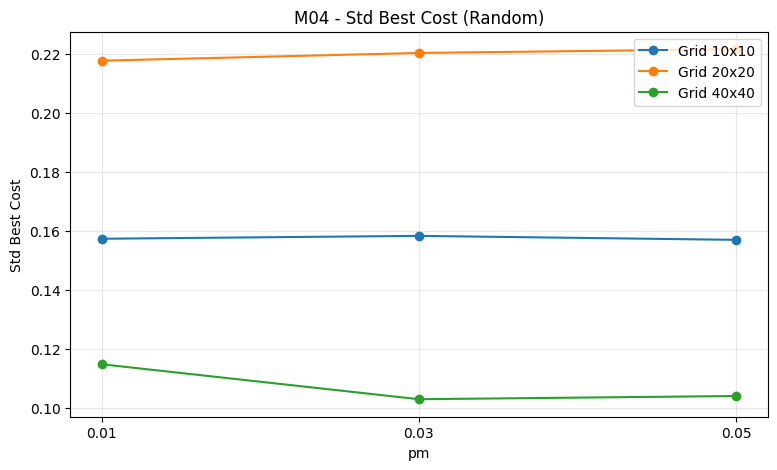

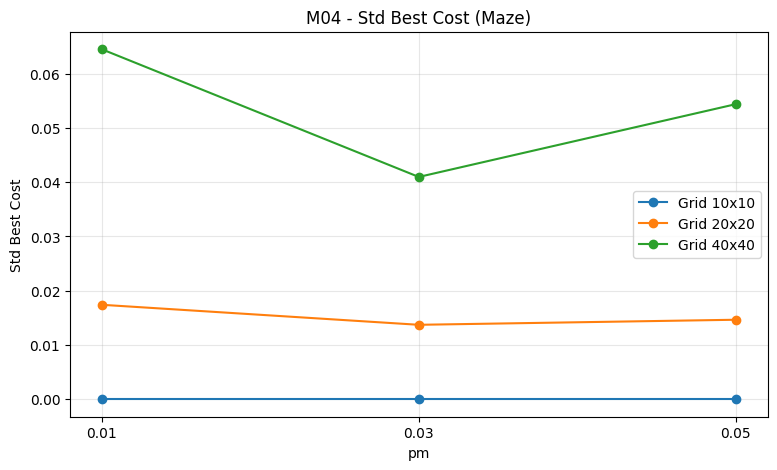

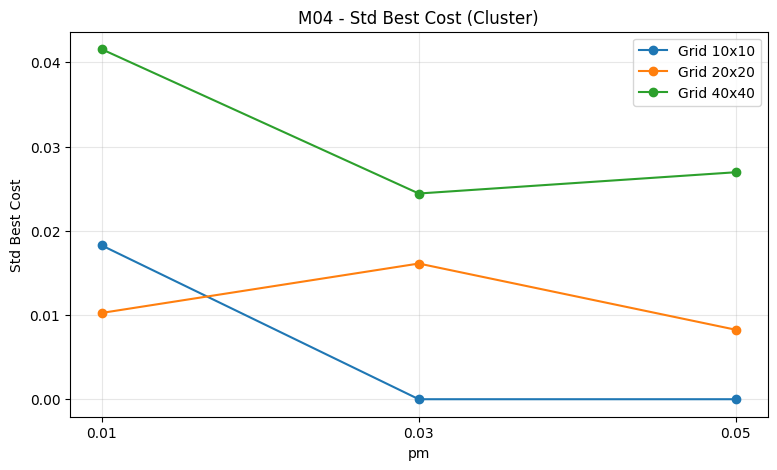

In [7]:
#std cost
map_types = ["Random", "Maze", "Cluster"]

for map_type in map_types:
    data = df_M04_Mutation_summary[
        df_M04_Mutation_summary["map_type"] == map_type
    ].copy()

    plt.figure(figsize=(9, 5))

    for grid_rows in sorted(data["grid_rows"].unique()):
        data_size = (
            data[data["grid_rows"] == grid_rows]
            .sort_values("pm")
        )

        plt.plot(
            data_size["pm"],
            data_size["std_cost"],
            marker="o",
            label=f"Grid {grid_rows}x{grid_rows}"
        )

    plt.title(f"M04 - Std Best Cost ({map_type})")
    plt.xlabel("pm")
    plt.ylabel("Std Best Cost")
    plt.xticks(sorted(data["pm"].unique()))
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()

In [8]:
#rank std cost
df_M04_Mutation_summary["rank_std_cost"] = (
    df_M04_Mutation_summary
    .groupby(["grid_rows", "map_type"])["std_cost"]
    .rank(method="average", ascending=True)
)

avg_rank_M04_std = (
    df_M04_Mutation_summary
    .groupby("pm", as_index=False)
    .agg(
        avg_rank_std=("rank_std_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_std_cost", "count")
    )
    .sort_values(["avg_rank_std", "avg_std_cost"])
)

print(avg_rank_M04_std)


     pm  avg_rank_std  avg_std_cost  jumlah_kombinasi
1  0.03      1.722222      0.064066                 9
2  0.05      1.833333      0.065179                 9
0  0.01      2.444444      0.071288                 9


In [9]:
summary_M04_time=(df_M04_Mutation.groupby(["grid_rows","pm", "map_type"], as_index=False).agg(
        mean_execTime=("execution_time_ms", "mean"),
        best_execTime=("execution_time_ms", "min"),
        worst_execTime=("execution_time_ms", "max"),
        std_Time=("execution_time_ms", "std"),
        total_runs=("execution_time_ms", "count")
    ))
display(summary_M04_time)
avg_time_by_population_m03 = (
    summary_M04_time.groupby("pm", as_index=False).agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    ).sort_values("avg_execTime")
)
display(avg_time_by_population_m03)
summary_time_pivot = summary_M04_time.pivot(
    index=["grid_rows", "pm"],
    columns="map_type",
    values="mean_execTime"
)
display(summary_time_pivot)

avg_time_by_map = (
    summary_M04_time.groupby(["map_type", "pm"], as_index=False).agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    ).sort_values(["map_type", "avg_execTime"])
)

print(avg_time_by_map)

,grid_rows,pm,map_type,mean_execTime,best_execTime,worst_execTime,std_Time,total_runs
0,10,0.01,Cluster,19.866667,11,36,5.575398,30
1,10,0.01,Maze,14.033333,8,28,4.874164,30
2,10,0.01,Random,21.916667,9,37,6.722821,60
3,10,0.03,Cluster,18.400000,12,35,6.536898,30
4,10,0.03,Maze,15.566667,10,25,4.074169,30
5,10,0.03,Random,26.216667,9,64,11.348250,60
6,10,0.05,Cluster,20.833333,11,43,9.161702,30
7,10,0.05,Maze,18.900000,10,39,8.486704,30
8,10,0.05,Random,23.983333,9,51,10.093615,60
9,20,0.01,Cluster,94.733333,68,127,14.801988,30


,pm,avg_execTime,avg_std_time,jumlah_kombinasi
0,0.01,1044.464815,255.033186,9
1,0.03,2593.977778,494.035796,9
2,0.05,3499.348148,686.921158,9


map_type            Cluster         Maze        Random
grid_rows pm                                          
10        0.01    19.866667    14.033333     21.916667
          0.03    18.400000    15.566667     26.216667
          0.05    20.833333    18.900000     23.983333
20        0.01    94.733333   105.933333    108.266667
          0.03   110.600000   119.533333    122.000000
          0.05   142.133333   148.133333    130.216667
40        0.01  3216.066667  2697.433333   3121.933333
          0.03  8171.533333  6811.966667   7949.983333
          0.05  9872.866667  9431.733333  11705.333333

  map_type    pm  avg_execTime  avg_std_time  jumlah_kombinasi
0  Cluster  0.01   1110.222222    291.089888                 3
1  Cluster  0.03   2766.844444    582.222675                 3
2  Cluster  0.05   3345.277778    774.147672                 3
3     Maze  0.01    939.133333    225.543021                 3
4     Maze  0.03   2315.688889    425.595467                 3
5     Maze  0.05   3199.588889    587.224721                 3
6   Random  0.01   1084.038889    248.466648                 3
7   Random  0.03   2699.400000    474.289245                 3
8   Random  0.05   3953.177778    699.391080                 3
